## Aco Hyperparameter Grid Search

Debido a que se noto un compartamiento extraño en como se comportaba el solver [aco](../solvers/aco.py) en simulaciones de distintos tamaños, se decidio hacer un analisis de como cambian los resultados para segun variamos los parametros. Por el momento solo nos concentramos en los parametros: `num_ants`, `num_iters`


### Importante

Mientras que se realizaba el analisis, pudimos encontrar un problema en la clase [synthetic](../data/generators/synthetic.py) que generaba instancias infeasibles para problemas de tamaño grande. El problema se basaba en como generaba las ventanas de tiempo de cada cliente.
En la version anterior del codigo, si bien se parametrizaba la longitud de la ventana con las variables, se utilizaba un random para generar las ventas de cada cliente en el rango debido segun la configuracion de [synthetic.yaml](../conf/generator/synthetic.yaml) pero no se tenia en cuanta la feasibilidad de esas instancias generadas. En cambio ahora lo que se hace es asignar customers a depots, verificando que se cumpla las restriciones de cargas, simular un recorrido y a partir de ahi armar las ventanas de tiempo para que la solucion sea feasible. De esta forma podemos asegurar la generacion de instancias feasibles a diferencia de antes que generabamos intancias y no sabiamos si el solver las marcaba infeasibles porque el mismo solver no encontraba la solucion o porque no existia solucion en si.

Se puede recrear el comportamiento corriendo los experimentos con el siguiente comando y restaurando la version del repo a la siguiente: `f6f3b71468f66270861a9fe196972cbbfd0d4eec`. El analisi siguiente se realizo luego de solucionar dicho error.

```bash
time python3 main.py -m \
  solvers.aco.num_ants=45000,.. \
  solvers.aco.num_iter=45000,... \
  solvers.aco.rho=0.40 \
  experiments.num_customers=30,... \
  experiments.num_vehicles=40,... \
  'experiments.name=aco_hyperparameter_C${experiments.num_customers}_V${experiments.num_vehicles}_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}_rho${solvers.aco.rho}'
```


### Objetivos

Se noto que ACO puede o no encontrar la solucion de una instancia dependiendo de los valores de $num_ants$ y $num_iters$$num_ants$ y $num_iters$.

El output de esta notebook, deberia ser una formula/aproximacion que dado $num vehicles$, $num customers$ fijos estime el valor de $num ants$ y $num iters$ tal que tenga la mayor probabilidad de encontrar la solucion.

Osea que tendriamos que:
1. Entender la relacion de las varaibles `num_ants` y `num_iters` con el tamaño del problema
2. Encontrar los valores optimos para cada tamaño de problema
3. Deducir una regla, funcion para los parametros

In [126]:
import sqlite3
import pandas as pd
from pathlib import Path
import re 
import numpy as np 
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
from sklearn.linear_model import LinearRegression

import psycopg2

DB_PATH = Path("../results/old_db_results.db")
sizes = ["small", "medium", "big", "large"]

def load_results_table(db_path: Path, table_name: str = "run_results") -> pd.DataFrame:
    # with sqlite3.connect(db_path) as conn:
    #     df = pd.read_sql_query(f"SELECT * FROM {table_name}", conn)

    conn = psycopg2.connect(
        dbname="results",
        user="tmarmay",
        password="tmarmay",
        host="localhost",
        port=5432
    )

    query = "SELECT * FROM run_results;"
    df = pd.read_sql(query, conn)
    conn.close()
    return df

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_ants(exp_id):
        m = re.search(r"ants(\d+)", exp_id)
        return int(m.group(1)) if m else np.nan

    def extract_it(exp_id):
        m = re.search(r"it(\d+)", exp_id)
        return int(m.group(1)) if m else np.nan

    def extract_C(text):
        match = re.search(r'C(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_V(text):
        match = re.search(r'V(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_rho(text):
        match = re.search(r'rho([0-9.]+)', text)
        return float(match.group(1)) if match else None

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["ants"] = df["experiment_id"].apply(extract_ants)
    df["it"] = df["experiment_id"].apply(extract_it)
    df["c"] = df["experiment_id"].apply(extract_C)
    df["v"] = df["experiment_id"].apply(extract_V)
    df["rho"] = df["experiment_id"].apply(extract_rho)
    df['dim'] = df['c'] + 2 * df['v']
    df["size"] = df["c"].apply(extract_size)

    rate = (
        df
        .groupby(['c','v','ants','it'])['feasible']
        .mean()
        .reset_index()
        .rename(columns={'feasible':'feasibility_rate'})
    )
    df['feasibility_rate'] = (
        df
        .groupby(['c','v','ants','it'])['feasible']
        .transform('mean')
    )

    return df

df = filter_by_experiment_prefix(df=load_results_table(DB_PATH), prefix="milpaco_")
df = prepare_dataframe(df)
df = df[(df['status'] != 'timeout') & (df['solver'] == 'ACO')]

/tmp/ipykernel_4413/50509340.py:29: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



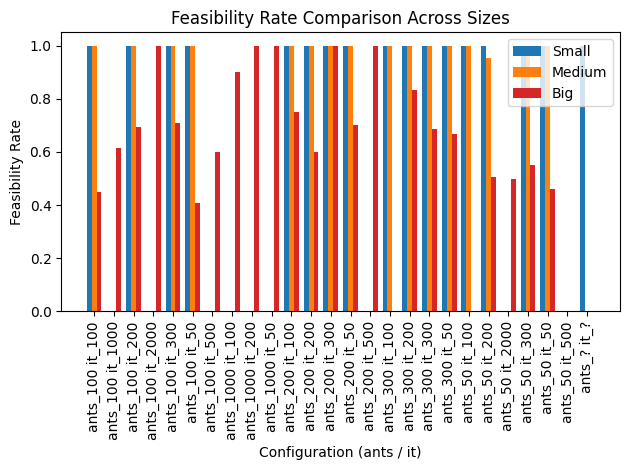

In [127]:
SIZE_COLORS = {
    "small": "tab:blue",
    "medium": "tab:orange",
    "big": "tab:red",
    "large": "yellow",
}


# Extract ants and it
def extract_label(exp_id):
    ants_match = re.search(r"ants(\d+)", exp_id)
    it_match = re.search(r"it(\d+)", exp_id)
    ants = ants_match.group(1) if ants_match else "?"
    it = it_match.group(1) if it_match else "?"
    return f"ants_{ants} it_{it}"

def plot_feasibility_all_sizes(df: pd.DataFrame):
    results = []

    for size in sizes:
        df_size = df[df["size"] == size].copy()

        if df_size.empty:
            continue

        summary = (
            df_size
            .groupby("experiment_id")["feasible"]
            .agg(["sum", "count"])
            .reset_index()
        )

        summary["feasibility_rate"] = summary["sum"] / summary["count"]
        summary["label"] = summary["experiment_id"].apply(extract_label)
        summary["size"] = size

        results.append(summary[["label", "feasibility_rate", "size"]])

    final_df = pd.concat(results)
    pivot_df = final_df.pivot_table(
        index="label",
        columns="size",
        values="feasibility_rate"
    ).fillna(0)

    pivot_df = pivot_df.sort_index()

    x = np.arange(len(pivot_df.index))
    width = 0.25

    plt.figure()
    for i, size in enumerate(sizes):
        if size in pivot_df.columns:
            plt.bar(
                x + i * width,
                pivot_df[size],
                width,
                label=size.capitalize(),
                color=SIZE_COLORS[size]
            )
    plt.xticks(x + width, pivot_df.index, rotation=90)
    plt.ylabel("Feasibility Rate")
    plt.xlabel("Configuration (ants / it)")
    plt.title("Feasibility Rate Comparison Across Sizes")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_feasibility_all_sizes(prepare_dataframe(df))

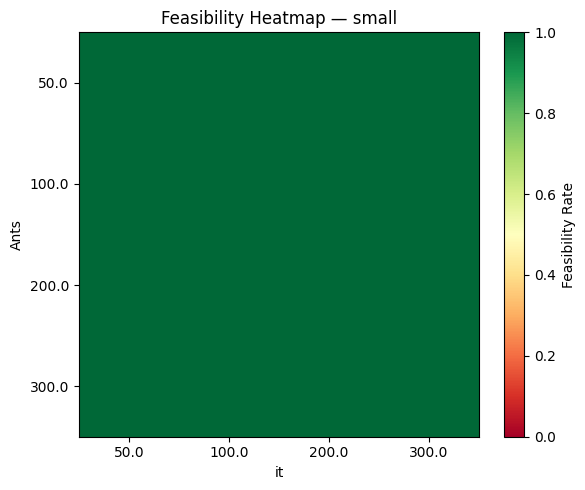

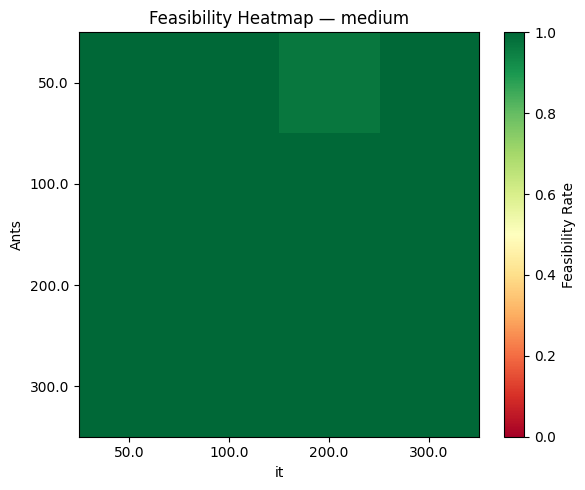

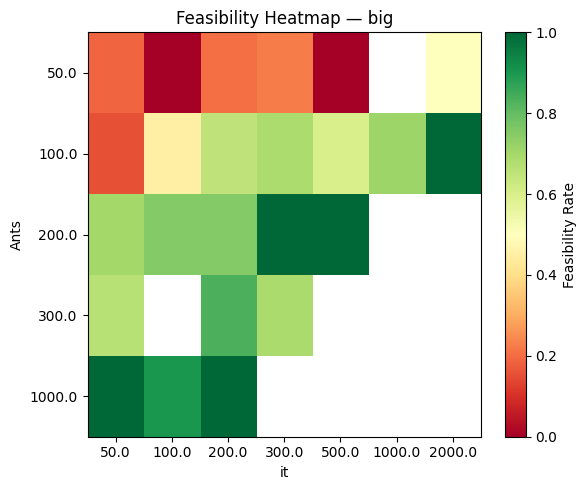

In [128]:
def heatmap_feasibility(df):

    for size in sizes:

        df_size = df[df["size"] == size]
        summary = (
            df_size
            .groupby(["ants", "it"])["feasible"]
            .mean()
            .reset_index()
        )

        if len(summary) == 0:
            continue
        
        pivot = summary.pivot(
            index="ants",
            columns="it",
            values="feasible"
        )

        pivot = pivot.sort_index().sort_index(axis=1)

        plt.figure(figsize=(6, 5))

        im = plt.imshow(
            pivot,
            aspect="auto",
            cmap="RdYlGn",
            vmin=0,
            vmax=1
        )

        plt.colorbar(im, label="Feasibility Rate")

        plt.xticks(range(len(pivot.columns)), pivot.columns)
        plt.yticks(range(len(pivot.index)), pivot.index)

        plt.xlabel("it")
        plt.ylabel("Ants")
        plt.title(f"Feasibility Heatmap — {size}")
        plt.tight_layout()
    plt.show()
heatmap_feasibility(df)

## Estado actual

Dado que hasta la fecha no pude encontrar una formula para estimar las ants-it para un c,v fijo ($f(c,v) = ants,it $), tome para casos medianos $ants=100$, $it=100$ y para casos grandes $ants=200$,  $it=300$. Respaldado por los heatmaps

In [129]:
def plot_3d_surface_cost_interactive(df: pd.DataFrame):
    for size in sizes:
        df_size = df[(df["size"] == size)]

        summary = (
            df_size
            .groupby(["ants", "it"])["feasible"]
            .mean()
            .reset_index()
        )

        if len(summary) == 0:
            continue

        pivot = summary.pivot(index="ants", columns="it", values="feasible")

        X = pivot.columns.values
        Y = pivot.index.values
        Z = pivot.values

        fig = go.Figure(data=[
            go.Surface(
                z=Z,
                x=X,
                y=Y,
                colorscale="Viridis",
                colorbar=dict(title="feasible")
            )
        ])

        fig.update_layout(
            title=f"Interactive 3D feasible Surface — {size}",
            scene=dict(
                xaxis_title="Iterations",
                yaxis_title="Ants",
                zaxis_title="feasible"
            ),
            autosize=True
        )
        fig.show()
plot_3d_surface_cost_interactive(df)

Intentemos ver si podemos encontrar alguna relacion entre ants-it y customers-vehicules:

### Ley de potencia

Proponemos $ants = a * c ^ \alpha * v ^ \beta$ 
- a: constante
- c: customers
- v : vehicles
- $ \alpha $ : factor de crecimiento c
- $ \beta $ : factor de crecimiento v

(de la misma forma para las iteraciones). Luego aplicamos log para bajar el exponente y nos queda una ecuacion de una recta. 

$$ ln(ants) = ln(a) + \alpha * ln(c) + \beta * ln(v) $$

Y hacemos una regrecion lineal multiple para estimar alfa y beta (no porque creemos que la relacion es lineal, sino porque llevamos el problema de exponencial a lineal). 

Luego lo que hacemos es graficar los puntos $$ln(ants_real) vs log(ants_predicho)$$ y si es parecido a una recta identidad es porque estan relacionados

Si:
- Si α = 0.8 → Un aumento del 1% en customers produce un aumento aproximado del 0.8% en ants óptimas.

In [130]:
# Porque estoy buscando la mejor configuración que logra factibilidad
df_f = df[(df['feasibility_rate'] > 0.8)]

# Para cada (c,v) deberías quedarte con las configuraciones mínimas que logran factibilidad.
df_f['ants-it'] = df_f['ants'] + df_f['it']

optimal = (
    df_f
    .sort_values('ants-it')
    .groupby(['c','v'])
    .first()
    .reset_index()
)



/tmp/ipykernel_4413/2607426296.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [131]:
def fit_multiple_power_law(best_df):

    # Variables independientes (log transformadas)
    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    # Variable dependiente
    y = np.log(best_df["ants"].values)

    model = LinearRegression()
    model.fit(X, y)

    alpha = model.coef_[0]   # exponente para c
    beta = model.coef_[1]   # exponente para v
    log_a = model.intercept_
    a = np.exp(log_a)

    r2 = model.score(X, y)

    print("Model: ants = a * c^alpha * v^beta")
    print(f"a      = {a:.4f}")
    print(f"alpha  = {alpha:.4f}  (influence of customers)")
    print(f"beta  = {beta:.4f}  (influence of vehicles)")
    print(f"R^2    = {r2:.4f}")

    return model


def plot_multiple_fit(best_df, model):

    # Construimos X nuevamente
    X = np.column_stack([
        # np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    # Valores reales
    y_real = np.log(best_df["ants"].values)

    # Valores predichos
    y_pred = model.predict(X)

    plt.figure()
    plt.scatter(y_real, y_pred)

    # Línea ideal y = x
    min_val = min(y_real.min(), y_pred.min())
    max_val = max(y_real.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val])

    plt.xlabel("Real log(Ants)")
    plt.ylabel("Predicted log(Ants)")
    plt.title("Multiple Power Law Fit (Ants)")
    plt.tight_layout()
    plt.show()


model_ants = fit_multiple_power_law(optimal)
plot_multiple_fit(optimal, model_ants)


Model: ants = a * c^alpha * v^beta
a      = 31.8814
alpha  = 0.2504  (influence of customers)
beta  = -0.1062  (influence of vehicles)
R^2    = 0.1477


ValueError: X has 1 features, but LinearRegression is expecting 2 features as input.

### Extensión con Polynomial Features

La ley de potencia asume una relación estructural específica (multiplicativa). Sin embargo, no hay garantía de que la relación real entre: customers (c) vehicles (v) ants óptimas siga exactamente esa forma funcional. Por eso probamos una aproximación más flexible usando expansión polinómica.

Partimos de un modelo lineal base: $ants = a + c ^ \alpha + v ^ \beta$ pero esto solo captura relaciones lineales simples.
Al aplicar PolynomialFeatures (grado 2) expandimos el espacio permitiendo modelar cosas como:
- Curvatura ($c^2$,$v^2$)
- interaccion entre variables v*c

Ahora el grafico representa real(ants) vs predict(ants)

R^2    = 0.0316


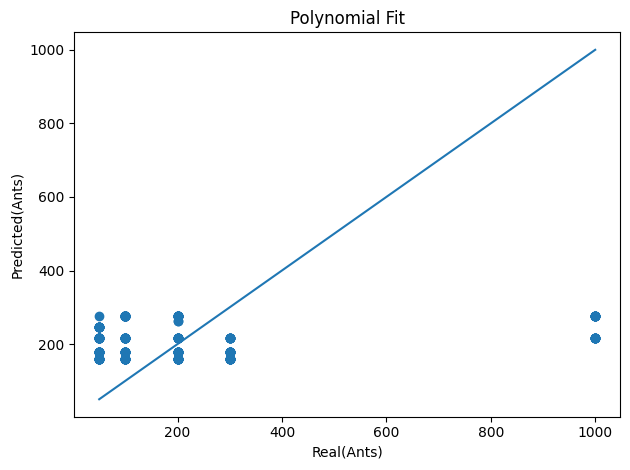

Coeficientes: [ 4.24269684 -0.02126155]
Intercepto: 139.34796847433842


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

def fit_polynomial_model(best_df, degree):

    # Variables en log
    X = np.column_stack([
        best_df["c"].values,
        best_df["v"].values
    ])

    y = best_df["ants"].values

    # Expandimos a polinomio
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    r2 = model.score(X_poly, y)
    print(f"R^2    = {r2:.4f}")

    return model, poly

def plot_polynomial_fit(best_df, model, poly):

    X = np.column_stack([
        best_df["c"].values,
        best_df["v"].values
    ])

    X_poly = poly.transform(X)

    y_real = best_df["ants"].values
    y_pred = model.predict(X_poly)

    plt.figure()
    plt.scatter(y_real, y_pred)

    min_val = min(y_real.min(), y_pred.min())
    max_val = max(y_real.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val])

    plt.xlabel("Real(Ants)")
    plt.ylabel("Predicted(Ants)")
    plt.title("Polynomial Fit")
    plt.tight_layout()
    plt.show()

model_poly, poly = fit_polynomial_model(optimal, degree=2)
plot_polynomial_fit(optimal, model_poly, poly)

print("Coeficientes:", model_poly.coef_)
print("Intercepto:", model_poly.intercept_)


Que pasa si no estoy teniendo suficientes instancias para el modelo ? fijemos un caso y con bastantes instacias y veamos si mejora

Model: ants = a * c^alpha * v^beta
a      = 131.6074
alpha  = 0.0000  (influence of customers)
beta  = 0.0000  (influence of vehicles)
R^2    = 0.0000


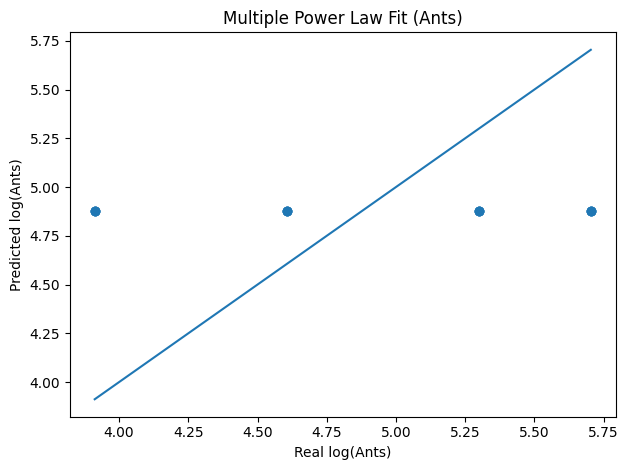

R^2    = 0.0000


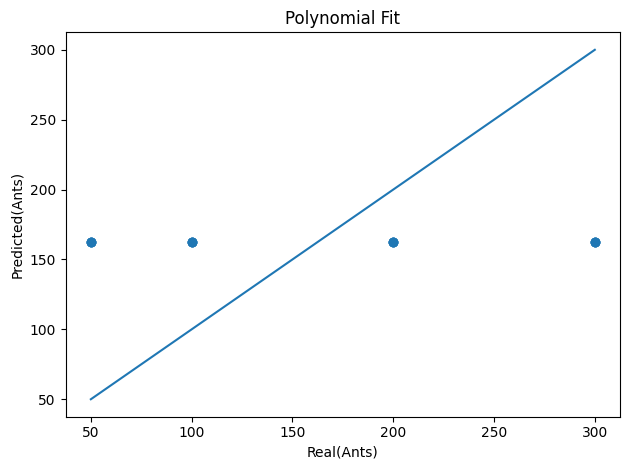

In [ ]:
vs = [40, 15, 10]
cs = [10, 30]

df_reduced = optimal[
    (optimal['v'].isin(vs)) &
    (optimal['c'].isin(cs))
]

model_ants2 = fit_multiple_power_law(df_reduced)
plot_multiple_fit(df_reduced, model_ants2)

model_poly2, poly2 = fit_polynomial_model(df_reduced, degree=2)
plot_polynomial_fit(df_reduced, model_poly2, poly2)

Preguntas luis
- Esta encaminado el analisis
- Estoy asumiendo algo mal 
- Esta bien el metodo o se usa otro
- Como defino una regla para correr las simulaciones
- Me conviene fijar combinaciones de c y v y ahi buscar ants-it optimo y no renegar ? igual quiero saber como puedo deducir una formula para el caso general

No es tan asi porque aca esta contando los runtime de las instancias sin solucion, pero noto que explota mas el tiempo cuando crece V y tiene cerrado por la formula de la cantidad de restricciones que se genera

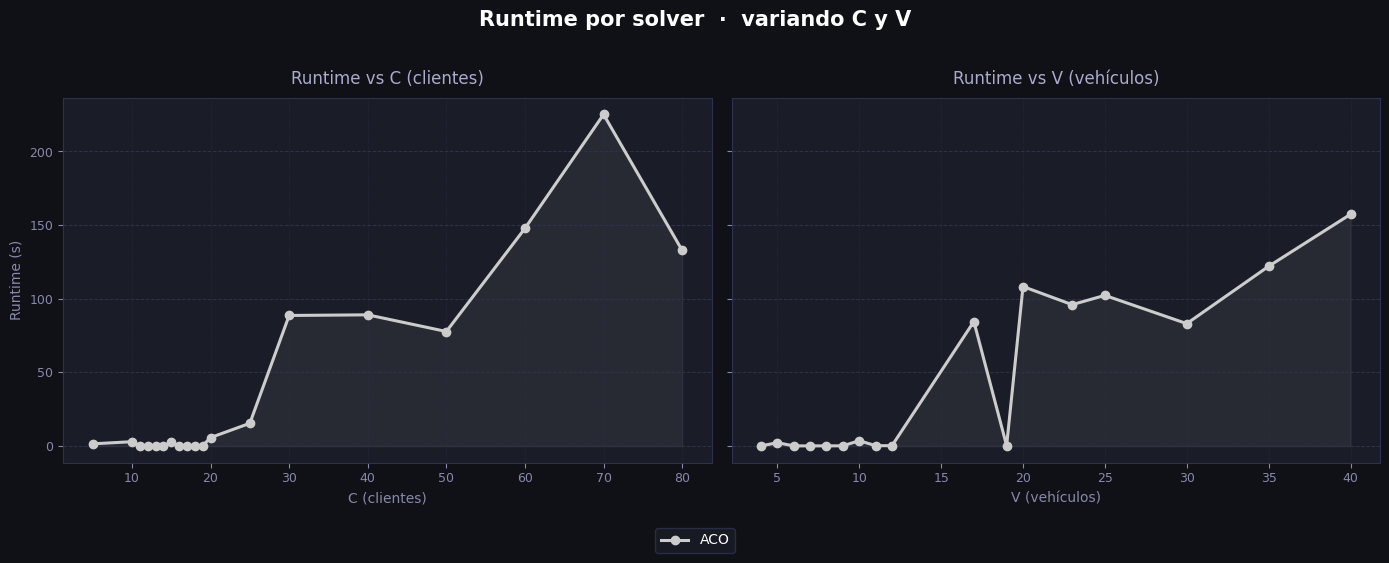

In [ ]:
import psycopg2
import pandas as pd
import re 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

SOLVER_COLORS = {
    "gurobi": "#E63946",   # rojo
    "glpk": "#2196F3",   # azul
    "cbc": "#4CAF50",   # verde
    "highs": "#FF9800",   # naranja
}
def plot_runtime_by_c_and_v(df: pd.DataFrame, solver_colors: dict = SOLVER_COLORS):
    solvers = ["ACO"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    fig.patch.set_facecolor("#0F1117")
    fig.suptitle(
        "Runtime por solver  ·  variando C y V",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    for ax, col, xlabel in zip(axes, ["c", "v"], ["C (clientes)", "V (vehículos)"]):
        ax.set_facecolor("#1A1D27")
        ax.set_title(f"Runtime vs {xlabel}", color="#AAAACC", fontsize=12, pad=10)

        for solver in solvers:
            color = solver_colors.get(solver, "#CCCCCC")
            s = (
                df[df["solver"] == solver]
                .groupby(col)["runtime"]
                .mean()
                .reset_index()
                .sort_values(col)
            )
            if s.empty:
                continue
            ax.plot(
                s[col], s["runtime"],
                marker="o", linewidth=2.2, markersize=6,
                color=color, label=solver,
            )
            ax.fill_between(s[col], s["runtime"], alpha=0.08, color=color)

        for spine in ax.spines.values():
            spine.set_edgecolor("#2E3250")
        ax.tick_params(colors="#8888AA", labelsize=9)
        ax.set_xlabel(xlabel, color="#8888AA", fontsize=10)
        ax.xaxis.set_major_locator(ticker.AutoLocator())
        ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
        ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    axes[0].set_ylabel("Runtime (s)", color="#8888AA", fontsize=10)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=len(solvers),
        facecolor="#1A1D27", edgecolor="#2E3250",
        labelcolor="white", fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()

plot_runtime_by_c_and_v(df)

       c     v   effort
0    5.0   5.0   2500.0
1    5.0  10.0   2500.0
2   10.0   5.0   2500.0
3   10.0  10.0   2500.0
4   11.0   4.0      NaN
..   ...   ...      ...
90  70.0  30.0   5000.0
91  70.0  35.0  60000.0
92  70.0  40.0  50000.0
93  80.0  20.0  20000.0
94  80.0  40.0  10000.0

[95 rows x 3 columns]

Puntos únicos (c,v): 95


<Axes: >

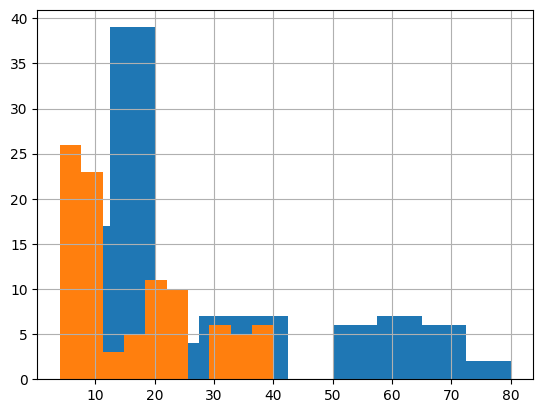

In [ ]:
# Para cada (c,v), mínimo esfuerzo feasible
df_min = (df[df['feasible'] == 1]
          .assign(effort = lambda x: x['ants'] * x['it'])
          .groupby(['c', 'v'])['effort']
          .min()
          .reset_index())

print(df_min)
print(f"\nPuntos únicos (c,v): {len(df_min)}")

df_min['c'].hist()
df_min['v'].hist()
